In [3]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = list(uploaded.keys())[0]
print(filename)

Saving auto-mpg.csv to auto-mpg (1).csv
auto-mpg (1).csv


In [4]:
df = pd.read_csv(filename, na_values="?")
print(df.shape)
print(df.isna().sum())
df.head()

(398, 9)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


In [5]:
df = df.dropna()
df = df.drop(columns="car name")
df = pd.get_dummies(df, columns=["origin"])
df.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin_1,origin_2,origin_3
0,18.0,8,307.0,130.0,3504,12.0,70,True,False,False
1,15.0,8,350.0,165.0,3693,11.5,70,True,False,False
2,18.0,8,318.0,150.0,3436,11.0,70,True,False,False
3,16.0,8,304.0,150.0,3433,12.0,70,True,False,False
4,17.0,8,302.0,140.0,3449,10.5,70,True,False,False


In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="mpg")
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(313, 9) (79, 9)


In [7]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lin = LinearRegression()
lin.fit(X_train, y_train)

pred = lin.predict(X_test)
print("R²  :", r2_score(y_test, pred))
print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

R²  : 0.7922774714022588
MAE : 2.4619996980661427
RMSE: 3.2561140968473956


In [8]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
print("RF R²  :", r2_score(y_test, pred_rf))
print("RF MAE :", mean_absolute_error(y_test, pred_rf))

RF R²  : 0.8879756194892279
RF MAE : 1.671550632911389


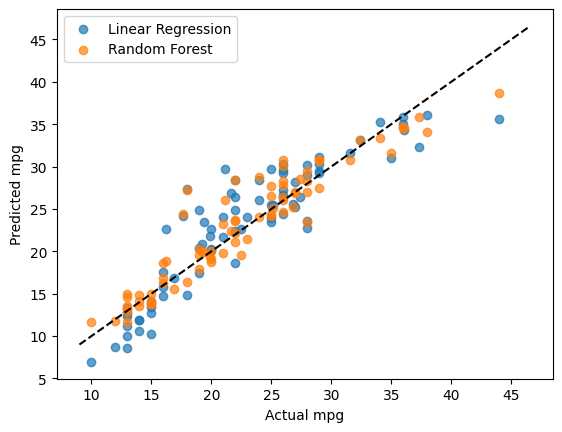

In [9]:
import matplotlib.pyplot as plt

plt.scatter(y_test, pred, label="Linear Regression", alpha=0.7)
plt.scatter(y_test, pred_rf, label="Random Forest", alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--")   # perfect-prediction line
plt.xlabel("Actual mpg")
plt.ylabel("Predicted mpg")
plt.legend()
plt.show()

In [10]:
new = pd.DataFrame([{"cylinders": 4, "displacement": 120, "horsepower": 90,
                     "weight": 2500, "acceleration": 15, "model year": 80,
                     "origin": 3}])
new = pd.get_dummies(new, columns=["origin"]).reindex(columns=X.columns, fill_value=0)

print("Linear regression:", lin.predict(new)[0])
print("Random forest    :", rf.predict(new)[0])

Linear regression: 31.21371638877447
Random forest    : 32.37649999999999
